# Giriş: Veri Görselleştirme

Bu ders, veri görselleştirme (data visualization) yolculuğunun ilk adımı. Önce veri görselleştirmenin ne olduğunu ve neden önemli olduğunu göreceğiz; sonra etkili bir görselleştirmenin arkasındaki tasarım ilkelerini konuşacağız ve yanıltıcı grafiklerdeki hataları avlamayı öğreneceğiz. Bu derste kod yazmayacaksın; amacımız görmeyi öğrenmek.

## 🎯 Bu Derste Ne Öğreneceğiz?

Bu dersin sonunda şunları yapabileceksin:

- Veri görselleştirmenin amacını ve önemini kendi cümlelerinle açıklamak
- Gözlerimizin sayı tabloları yerine grafiklerden neden daha hızlı anladığını söylemek
- Etkili bir görselleştirmenin temel tasarım ilkelerini (basitlik, tutarlılık, denge, vurgu, renk) tanımak
- Yaygın yanıltıcı grafik hatalarını fark etmek ve neyin yanlış olduğunu gerekçelendirmek

Bu ders, kursun 1. öğrenme çıktısının temelini oluşturuyor.

## 💡 Neden Bu Konuyu Öğreniyoruz?

Günlük hayatta sürekli grafiklerle karşılaşıyorsun: hava durumu uygulamasındaki sıcaklık eğrisi, haber sitesindeki seçim anketi çubukları, telefonundaki adım sayacı özeti, banka uygulamasındaki harcama dağılımı... Bunların ortak noktası ne? Hepsi, tek başına bakıldığında anlamsız görünen yüzlerce sayıyı birkaç saniyede anlaşılır hâle getiriyor.

Bir de işin diğer tarafı var: yanlış yapılmış bir grafik, doğru yapılmış bir analizden daha kolay yanıltabilir. Kesilmiş bir eksen, gereksiz bir üç boyut efekti ya da parıltılı renkler, izleyicinin veriden yanlış sonuçlar çıkarmasına yol açabilir. Bu yüzden grafik okumak da grafik üretmek kadar beceri gerektirir.

Bu kursta hem kendi verinden anlamlı grafikler üretmeyi hem de karşına çıkan grafikleri eleştirel bir gözle okumayı öğreneceksin. Bu ders, o becerinin kavramsal temelini atıyor.

## 🔗 Ön Bilgi

Bu kursun ilk dersi; önceki bir derse ihtiyacın yok.

> **Önemli:** Bu defterde kod hücreleri ve grafikler göreceksin, ancak bu derste kodu çalıştırman beklenmiyor. Ortamını 3. derste (Ortam Kurulumu) kuracaksın; o zamana kadar grafikleri defterin içinde hazır hâlleriyle incelemen yeterli. Kod tarafıyla ilgilenmek istersen 7. derste matplotlib'i ayrıntılı öğreneceğiz.

## 🔍 Birlikte Keşfedelim

Bir düşün: bir internet sitesinin aylık ziyaretçi sayılarını elinde tutuyorsun. Yönetici sana "sitenin gidişatı nasıl?" diye soruyor. Elinde yalnızca şu tablo var:

| Ay | Ziyaretçi (bin) |
|---|---|
| Ocak | 120 |
| Şubat | 135 |
| Mart | 150 |
| Nisan | 148 |
| Mayıs | 170 |
| Haziran | 190 |
| Temmuz | 210 |
| Ağustos | 205 |
| Eylül | 230 |
| Ekim | 260 |
| Kasım | 290 |
| Aralık | 310 |

**Tahminin:** Tabloya on saniye bak ve şu soruları yanıtla: Ziyaretçi sayısı hangi ayda en yüksek? Genel eğilim artış mı, düşüş mü? Düşüş yaşanan aylar var mı? Cevaplarını düşün ve istersen bu hücreye yaz; sonra aşağıdaki grafiği incele.

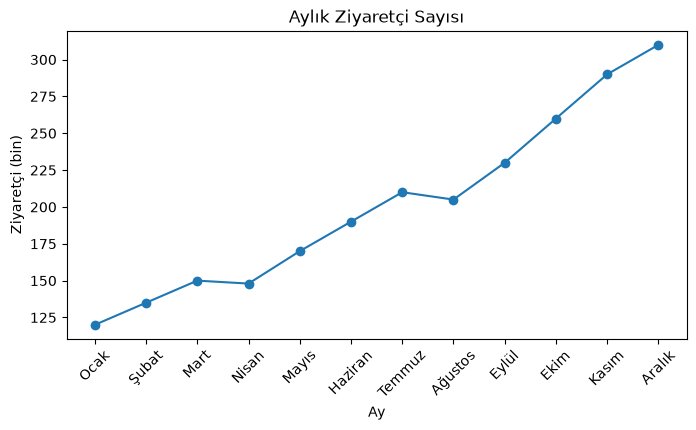

In [1]:
import matplotlib.pyplot as plt

aylar = ['Ocak', 'Şubat', 'Mart', 'Nisan', 'Mayıs', 'Haziran',
         'Temmuz', 'Ağustos', 'Eylül', 'Ekim', 'Kasım', 'Aralık']
ziyaretci = [120, 135, 150, 148, 170, 190, 210, 205, 230, 260, 290, 310]

plt.figure(figsize=(8, 4))
plt.plot(aylar, ziyaretci, marker='o')
plt.title('Aylık Ziyaretçi Sayısı')
plt.xlabel('Ay')
plt.ylabel('Ziyaretçi (bin)')
plt.xticks(rotation=45)
plt.show()

**Gözlem:** Tablodan saniyeler süren sorular, grafiğe bakınca anında yanıtlanıyor: genel artış eğilimi, Nisan ve Ağustos'taki küçük düşüşler, yıl sonuna doğru hızlanan artış... hepsi gözünün önünde.

İşte veri görselleştirmenin özü bu: aynı veri, farklı sunum, bambaşka bir okuma hızı. İnsan gözü ve beyni, konum ve uzunluk farklarını olağanüstü hızlı işler; sayı tablosundaysa her karşılaştırma için zihinsel hesap yapman gerekir. Bu kurstaki tüm konular, bu hız avantajını doğru ve dürüst kullanma sanatına dayanıyor.

## 📖 Kavramlar

### Veri görselleştirme nedir?

**Veri görselleştirme (data visualization)**, verileri grafik, harita, diyagram gibi görsel biçimlere dönüştürerek bilgi ve içgörü (insight) elde etmeyi kolaylaştıran süreçtir. İki temel amacı vardır:

1. **Keşif:** Kendin için. Veriyi tanırken örüntüleri, aykırılıkları ve ilişkileri görmeni sağlar. (6. derste keşfedici veri analizinde bu konuya döneceğiz.)
2. **İletişim:** Başkaları için. Bulgularını hedef kitleye hızlı ve etkili biçimde aktarmanı sağlar. (15. derste hikâyeleştirmede bu konuya döneceğiz.)

> **Not:** Aynı grafik her iki amaç için uygun olmayabilir. Kendi keşfin için hızlıca ürettiğin kaba bir grafik, sunum için sadeleştirilmek zorunda kalabilir.

### Görsel algı: neden grafikler daha hızlı?

İnsan gözü bazı görsel karşılaştırmalarda çok iyidir: iki çubuğun uzunluğu, iki noktanın konumu, bir çizginin eğimi... Bazılarında ise zayıftır: pasta dilimlerinin açıları, dairelerin alanları, renk tonları arasındaki ince farklar. Bu yüzden aynı veriyi göstermenin "kolay okunan" ve "zor okunan" yolları vardır. Çubuk grafiğinin çoğu zaman pasta grafiğinden daha okunabilir olmasının nedeni budur: uzunluk karşılaştırması, açı karşılaştırmasından kolaydır.

### Tasarım ilkeleri

- **Basitlik:** Gereksiz her öğe (aşırı ızgara çizgileri, süslemeler, efektler) mesajdan dikkat çalar. İyi bir grafik, bir haber gibi tek bir ana mesaj taşır.
- **Tutarlılık:** Renk, ölçek ve biçim tutarlı kalırsa okuyucu her grafiği yeniden öğrenmek zorunda kalmaz.
- **Denge:** Öğelerin yerleşimi gözü yormamalı; etiketler okunabilir ve yerli yerinde olmalı.
- **Vurgu:** Ana mesajı taşıyan öğe öne çıkmalı, geri kalanlar sade kalmalı. (Bu dersteki "Deneyelim" bölümünde bunun canlı bir örneğini göreceksin.)
- **Renk:** Renk bilgi taşıyorsa kullanılmalı; "daha renkli" genelde "daha iyi" değildir.

### Etkili görselleştirme süreci

İyi bir grafik tesadüf eseri ortaya çıkmaz; kabaca şu akış izlenir:

![Etkili görselleştirme sürecinin beş adımı: soru, veriyi tanıma, grafik türünü seçme, tasarım ilkelerini uygulama ve içgörüyü paylaşma](../Assets/01-Visualization-Process.png)

Diyagramdaki akışın özü şu cümlede: soru → veriyi tanı → grafik türünü seç → tasarım ilkelerini uygula → içgörüyü paylaş. Bu akışın her adımını kursta ayrıntılı işleyeceğiz: 2. derste grafik seçimini, 5-6. derste veriyi tanımayı, 7. dersten itibaren üretmeyi, 15. derste paylaşmayı öğreneceksin.

### Yanıltıcı grafikler

Grafikler iyi niyetli hatalarla da kasıtlı çarpıtmalarla da yanıltabilir. En yaygın beş hata:

1. **Kesik eksen:** Çubuk grafiğin dikey ekseni sıfırdan değil de yüksek bir değerden başlatılırsa küçük farklar dev gibi görünür.
2. **Yersiz üç boyut:** 3B efektler derinlik algısı yarattığı için dilimlerin ve çubukların büyüklüğünü çarpıtır.
3. **Aşırı renk ve efekt:** Parlak renkler, gölgeler, patlayan dilimler mesajı değil süsü öne çıkarır.
4. **Kalabalık grafik:** Tek grafikte onlarca seri ya da kategori göstermek okumayı imkânsızlaştırır.
5. **Eksik bağlam:** Ölçek, birim ya da zaman aralığı belirtilmezse grafik istenildiği gibi yorumlanır.

Aşağıdaki hücre aynı veriyle kesik eksenli ve düzgün iki grafik üretiyor. İkisini karşılaştır:

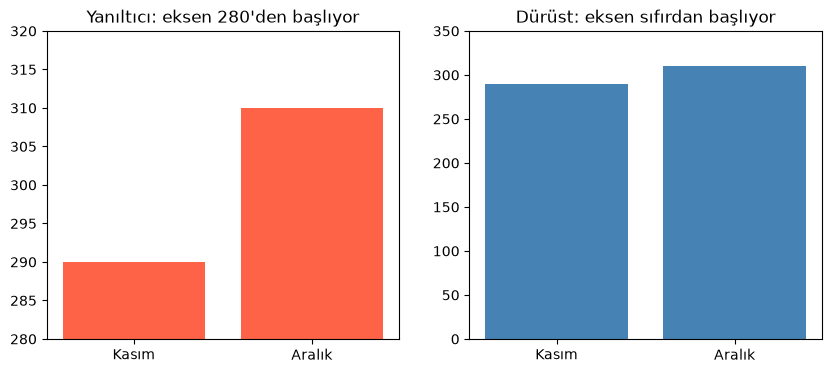

In [2]:
import matplotlib.pyplot as plt

son_aylar = ['Kasım', 'Aralık']
son_ziyaretci = [290, 310]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.bar(son_aylar, son_ziyaretci, color='tomato')
ax1.set_ylim(280, 320)
ax1.set_title("Yanıltıcı: eksen 280'den başlıyor")

ax2.bar(son_aylar, son_ziyaretci, color='steelblue')
ax2.set_ylim(0, 350)
ax2.set_title('Dürüst: eksen sıfırdan başlıyor')

plt.show()

Soldaki grafikte Aralık çubuğu Kasım'ın iki katı gibi görünüyor; oysa fark yalnızca 20 bin, yani yaklaşık %7. Sağdaki grafik aynı veriyi gerçek oranlarıyla gösteriyor.

> **Not:** "Eksen her zaman sıfırdan başlamalı mı?" sorusunun yanıtı grafik türüne bağlıdır. Uzunluk karşılaştırmaya dayanan çubuk grafiklerde evet: kesik eksen oranı bozar. Değişimi izlemeye dayanan çizgi grafiklerde ise bazı durumlarda anlamlı bir aralık kullanmak kabul edilebilir; önemli olan izleyicinin orandan yanılmamasıdır.

## 🛠️ Uygulama

Söz verdiğimiz gibi bu derste kod yazmıyoruz; ama "bu işin kod tarafı nasıl görünüyor?" merakını giderelim. Aşağıdaki hücre, keşif bölümündeki ziyaretçi verisinin yalnızca son dört ayını çubuk grafiğe döküyor. Şimdilik satır satır anlamak zorunda değilsin; 7. derste matplotlib'i baştan sona öğreneceğiz.

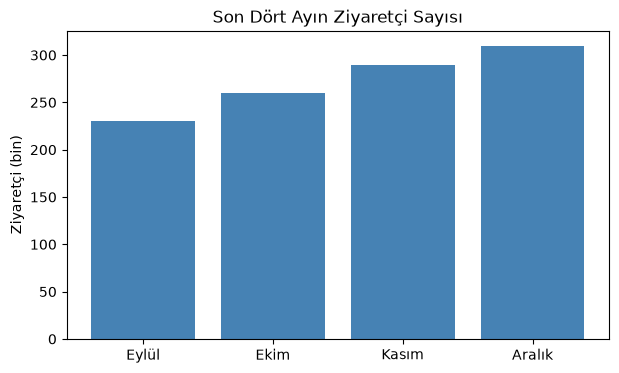

In [3]:
import matplotlib.pyplot as plt

dort_ay = ['Eylül', 'Ekim', 'Kasım', 'Aralık']
dort_ziyaretci = [230, 260, 290, 310]

plt.figure(figsize=(7, 4))
plt.bar(dort_ay, dort_ziyaretci, color='steelblue')
plt.title('Son Dört Ayın Ziyaretçi Sayısı')
plt.ylabel('Ziyaretçi (bin)')
plt.show()

Üç şey fark et: (1) grafik birkaç satır kodla üretiliyor; (2) başlık ve eksen adı kodun içinde açıkça yazılıyor, yani grafikle birlikte tasarlanıyorlar; (3) renk bilinçli tek bir seçim. Kursun ikinci yarısında bu kodları kendin yazacaksın; şimdilik "grafik = kod + tasarım kararları" fikrine alışman yeterli.

## 🧪 Deneyelim ve Gözlemleyelim

Şimdi hata avına çıkalım. Aşağıda iki grafik çifti var; her çiftte soldaki kötü, sağdaki iyi tasarlanmış aynı veri var. Her çift için soldaki grafikteki tasarım hatalarını bul ve hangi ilkeleri ihlal ettiğini düşün. Cevaplar defterin sonundaki "Cevaplar" bölümünde; ama önce kendi aramanı yap.

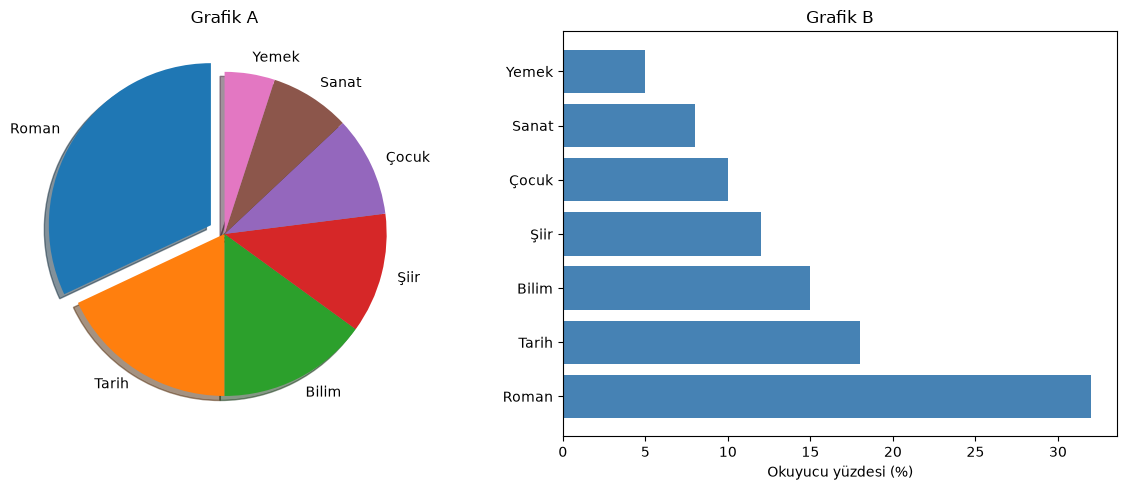

In [4]:
import matplotlib.pyplot as plt

kategoriler = ['Roman', 'Tarih', 'Bilim', 'Şiir', 'Çocuk', 'Sanat', 'Yemek']
okuyucu = [32, 18, 15, 12, 10, 8, 5]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.pie(okuyucu, labels=kategoriler, explode=[0.1, 0, 0, 0, 0, 0, 0],
        shadow=True, startangle=90)
ax1.set_title('Grafik A')

ax2.barh(kategoriler, okuyucu, color='steelblue')
ax2.set_xlabel('Okuyucu yüzdesi (%)')
ax2.set_title('Grafik B')

plt.tight_layout()
plt.show()

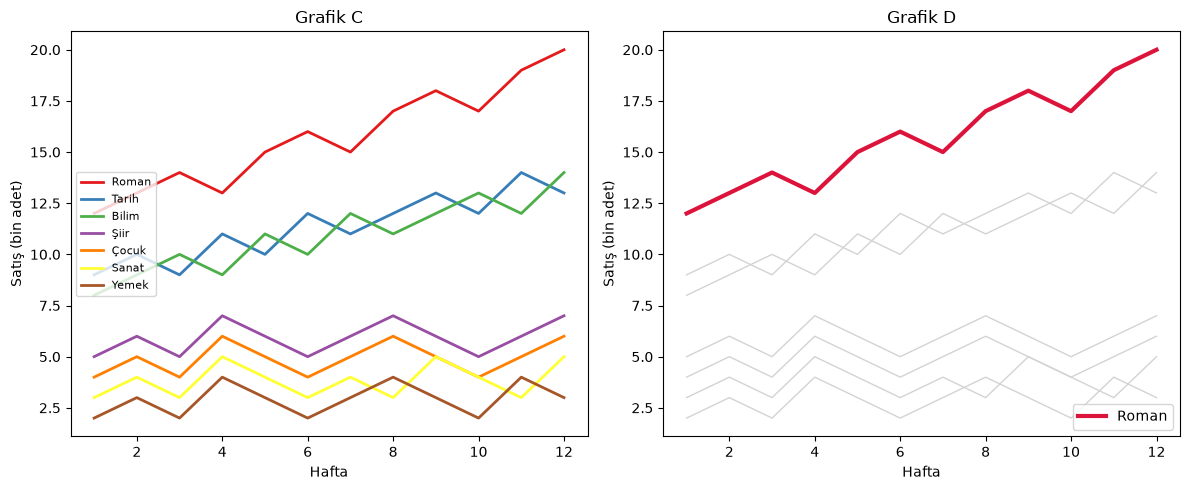

In [5]:
import matplotlib.pyplot as plt

haftalar = list(range(1, 13))
seriler = {
    'Roman': [12, 13, 14, 13, 15, 16, 15, 17, 18, 17, 19, 20],
    'Tarih': [9, 10, 9, 11, 10, 12, 11, 12, 13, 12, 14, 13],
    'Bilim': [8, 9, 10, 9, 11, 10, 12, 11, 12, 13, 12, 14],
    'Şiir': [5, 6, 5, 7, 6, 5, 6, 7, 6, 5, 6, 7],
    'Çocuk': [4, 5, 4, 6, 5, 4, 5, 6, 5, 4, 5, 6],
    'Sanat': [3, 4, 3, 5, 4, 3, 4, 3, 5, 4, 3, 5],
    'Yemek': [2, 3, 2, 4, 3, 2, 3, 4, 3, 2, 4, 3],
}
renkler = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3',
           '#ff7f00', '#ffff33', '#a65628']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

for (ad, degerler), renk in zip(seriler.items(), renkler):
    ax1.plot(haftalar, degerler, label=ad, color=renk, linewidth=2)
ax1.set_title('Grafik C')
ax1.set_xlabel('Hafta')
ax1.set_ylabel('Satış (bin adet)')
ax1.legend(loc='center left', fontsize=8)

for ad, degerler in seriler.items():
    if ad == 'Roman':
        ax2.plot(haftalar, degerler, color='crimson', linewidth=3, label='Roman')
    else:
        ax2.plot(haftalar, degerler, color='lightgray', linewidth=1)
ax2.set_title('Grafik D')
ax2.set_xlabel('Hafta')
ax2.set_ylabel('Satış (bin adet)')
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()

İki çifti karşılaştırırken kendine sor: hangi grafikte ana mesajı ilk bakışta görebildin? Grafik A ve C'de hangi yanıltıcı grafik hataları bir arada? Grafik B ve D aynı veriyi nasıl tek bir ana mesaj etrafında düzenliyor?

## 🏋️ Kendin Dene

Bir haber sitesinde, gazetede ya da sosyal medyada bulduğun bir grafiği bu derste öğrendiğin ilkelerle değerlendir:

1. Grafiğin ana mesajı ne? Tek cümleyle söyleyebiliyor musun?
2. Beş tasarım ilkesinden (basitlik, tutarlılık, denge, vurgu, renk) hangileri karşılanmış, hangileri ihmal edilmiş?
3. Yukarıdaki beş yanıltıcı grafik hatasından birini taşıyor mu?


## 🧠 Öğrendiklerini Kontrol Et

Cevaplar defterin sonundaki "Cevaplar" bölümünde. Önce kendin dene.

1. Veri görselleştirmenin iki temel amacını yaz ve her birine günlük hayattan birer örnek ver.
2. Bir çubuk grafiğin dikey ekseni 280'den başlıyor ve iki çubuk arasındaki yaklaşık %7'lik fark iki kat gibi görünüyor. Bu grafik hangi yanıltıcı hata örneğidir ve izleyicide neye yol açar?
3. İnsan gözü hangi karşılaştırmalarda iyidir, hangilerinde zayıftır? Bunun pasta grafiğiyle çubuk grafiği seçimine etkisi nedir?
4. Grafik D, Grafik C'deki aynı veriyi nasıl daha okunabilir hâle getirdi? Hangi ilkeyi nasıl uyguladı?
5. Bir grafikteki her çubuk farklı parlak renkte boyanmış ve hiçbir renk bir anlam taşımıyor. Bu durum hangi iki ilkeyi zedeliyor?
6. Doğru mu yanlış mı: "Bir grafikte ne kadar çok seri, renk ve efekt varsa o kadar bilgilendiricidir." Gerekçenle açıkla.

## 🚀 Bağımsız Çalışma

- **Hata avı görevi:** "Misleading graph" (yanıltıcı grafik) konulu haber ve yazılarda gerçek örnekler bul. Bir örneği seç, hatasını ve izleyicide yaratabileceği yanılgıyı bir paragrafla yaz. İstersen bir sonraki derste arkadaşlarınla paylaş.
- **Mini deney:** Bu dersteki ziyaretçi tablosunu bir arkadaşına önce tablo olarak göster; "eğilim ne?" diye sor ve süreyi ölç. Sonra grafiği göster ve aynı soruyu sor. Hangisi daha hızlı yanıt aldı? Deneyimini kısaca not et.

## 📚 Daha Fazlasını Öğrenmek

- Edward R. Tufte — *The Visual Display of Quantitative Information* (grafik tasarımın klasikleşmiş kitabı)
- Cole Nussbaumer Knaflic — *Storytelling with Data* (veriyle anlatım; 15. derste yeniden karşımıza çıkacak)
- Vikipedi'deki "Misleading graph" maddesi (yanıltıcı grafik türleri ve gerçek örnekler)

Bu kaynaklar İngilizce. Türkçe bir kaynak bulursan etrafındakilerle paylaş.

## ✅ Kısa Özet

- Veri görselleştirme, veriden bilgi ve içgörü elde etmeyi kolaylaştırır; iki amacı vardır: **keşif** ve **iletişim**.
- Göz, uzunluk ve konum karşılaştırmalarında hızlıdır; açı ve alan karşılaştırmalarında yavaştır. Bu yüzden çubuk grafiği genelde pasta grafiğini yener.
- Etkili grafik beş ilkeye dayanır: **basitlik, tutarlılık, denge, vurgu, renk**.
- Yaygın yanıltıcı hatalar: kesik eksen, yersiz üç boyut, aşırı renk ve efekt, kalabalık grafik, eksik bağlam.
- İyi grafik tek bir ana mesaj taşır ve onu öne çıkarır.

Sıradaki derste bu ilkeleri somut bir karara çevireceğiz: elimizdeki veri için doğru grafik türünü nasıl seçeriz?

---

[← Kursun genel bakışına dön](../README.md) · [Sıradaki ders: Grafik Türleri ve Doğru Seçim →](02-Chart-Types.ipynb)

## Cevaplar

### Deneyelim: Grafik A ve Grafik B

Grafik A (pasta) üç hatayı bir arada işliyor: yedi dilim var ve açıları karşılaştırmak zordur; "patlayan" ilk dilim ile gölge efekti dikkati mesajdan çok süse verir; yedi farklı renk grafiği kalabalıklaştırır. Yani aşırı renk/efekt ve kalabalık grafik hataları birlikte görülüyor. Grafik B aynı veriyi uzunluk karşılaştırmalarıyla ve tek renkle gösterir; okunması saniyeler sürer. (Pasta grafiği iki-üç dilimle sınırlı kaldığında kabul edilebilir; burada yedi dilim fazlasıyla çok.)

### Deneyelim: Grafik C ve Grafik D

Grafik C'de yedi seri yedi farklı parlak renkle çizilmiş; hangi çizginin önemli olduğu belli değil, gösterge ortada duruyor ve okunması güç. Kalabalık grafik, aşırı renk ve zayıf vurgu bir arada. Grafik D aynı veride ana mesajı öne çıkarıyor: Roman serisi kalın ve kırmızı, diğer altı seri açık gri; gözün takip etmesi gereken tek çizgi kalıyor. Vurgu ilkesinin tipik bir örneği.

### Kontrol Et 1

Keşif: kendi analizinde örüntüleri görmek (örneğin bu dersteki ziyaretçi grafiğini ilk inceleyişin). İletişim: bulgunu başkasına aktarmak (örneğin yöneticiye sunulan aylık rapor grafiği).

### Kontrol Et 2

Kesik eksen hatası. Çubuk uzunlukları orantısız büyütüldüğü için küçük fark büyük bir fark gibi algılanır; izleyici verinin gösterdiğinden fazlasını varsayabilir.

### Kontrol Et 3

Göz uzunluk ve konum karşılaştırmalarında iyidir; açı, alan ve ince renk tonu karşılaştırmalarında zayıftır. Pasta grafiği açı karşılaştırmasına, çubuk grafiği uzunluk karşılaştırmasına dayandığı için çubuk genelde daha kolay okunur.

### Kontrol Et 4

Vurgu ilkesini uyguladı: ana mesajı taşıyan Roman serisi kalın ve kırmızı çizgiyle öne çıkarıldı, geri kalan altı seri açık griyle geri plana itildi. Gösterge sadeleşti ve gözün takip etmesi gereken tek çizgi kaldı.

### Kontrol Et 5

Renk (renk bilgi taşımıyor, yalnızca süs olmuş) ve basitlik (gereksiz öğeler dikkati bölüyor) ilkeleri zedeleniyor.

### Kontrol Et 6

Yanlış. Renk ve efekt kalabalığı mesajı geri plana iter; bilgilendiren şey verinin net sunumudur, süs değildir. Grafik D bunun kanıtı: aynı veri daha az renkle daha çok şey anlatıyor.

### İpuçları

**Kendin Dene:** Grafikte şunları kontrol et: eksen sıfırdan başlıyor mu? Renkler bir şey anlatıyor mu yoksa süs mü? Tek bakışta görebildiğin bir ana mesaj var mı? Kaç seri ya da kategori var; hepsi gerekli mi? Kaynak, birim ve zaman aralığı belirtilmiş mi?
